# Pattern-Matching NILM

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from fastdtw import fastdtw
import pickle

## Directories

In [2]:
base_dir = os.getcwd()
processed_data_dir = os.path.join(base_dir, 'processed_data')

results_dir = os.path.join(base_dir, 'results')
os.makedirs(results_dir, exist_ok=True)

## Load Data

In [3]:
processed_data_filepath = os.path.join(base_dir, 'processed_data', 'ampds_dataset.npz')
processed_data = np.load(processed_data_filepath)

# Check Data
print(f'Processed Data Items: {processed_data.files}')

Processed Data Items: ['electrical_quantities', 'appliance_names', 'agg_norm', 'apps_norm', 'agg_min', 'agg_max', 'apps_min', 'apps_max', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'window_length', 'stride']


In [4]:
print(f'Electrical Quantities: {processed_data['electrical_quantities']}')
print(f'Appliance Names: {processed_data['appliance_names']}')
print(f'Number Timestamps: {processed_data['T']}')

window_length = processed_data['window_length']
print(f'Window Length: {window_length}')
print(f'Stride: {processed_data['stride']}')

Electrical Quantities: ['P-agg' 'I-agg' 'Q-agg' 'S-agg']
Appliance Names: ['RSE' 'GRE' 'B1E' 'BME' 'CWE' 'DWE' 'EQE' 'FRE' 'HPE' 'OFE' 'UTE' 'WOE'
 'B2E' 'CDE' 'DNE' 'EBE' 'FGE' 'HTE' 'OUE' 'TVE']
Number Timestamps: 1000
Window Length: 30
Stride: 1


In [5]:
agg_norm = processed_data['agg_norm']
apps_norm = processed_data['apps_norm']
agg_column_labels = ["id", "time"] + processed_data["electrical_quantities"].tolist()
apps_column_labels = ["id", "time"] + processed_data["appliance_names"].tolist()

display(pd.DataFrame(
    agg_norm,
    columns=agg_column_labels)
    .head().style.format("{:.2f}").set_caption('Aggregate Measurements')
    .hide(axis='index'))

display(pd.DataFrame(
    apps_norm,
    columns=apps_column_labels)
    .head().style.format('{:.2f}').set_caption('Appliance-Level Measurements (P Only)')
    .hide(axis='index'))

id,time,P-agg,I-agg,Q-agg,S-agg
0.00,0.00,0.11,0.05,0.03,0.10
0.00,0.00,0.11,0.05,0.03,0.10
0.00,0.00,0.10,0.05,0.03,0.09
0.00,0.00,0.10,0.05,0.03,0.09
0.00,0.00,0.09,0.05,0.03,0.09


id,time,RSE,GRE,B1E,BME,CWE,DWE,EQE,FRE,HPE,OFE,UTE,WOE,B2E,CDE,DNE,EBE,FGE,HTE,OUE,TVE
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.67,0.29,0.01,0.27,1.00,0.00,0.74,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.00,0.00,0.74,0.00,0.00,0.33,0.36,0.01,0.27,1.00,0.00,0.74,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.67,0.36,0.01,0.27,1.00,0.00,0.01,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.61,0.29,0.01,0.27,1.00,0.00,0.00,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.61,0.29,0.01,0.27,1.00,0.00,0.01,0.00,1.00,0.00,0.00,0.02,0.00,0.00


In [6]:
print(f'Train/Val/Test Split: {processed_data['train_val_test_split']}')

train_indices = processed_data['train_indices']
val_indices = processed_data['val_indices']
test_indices = processed_data['test_indices']

print(f"Training Indices ({len(train_indices)} Total): {train_indices[:10]}...")
print(f"Validation Indices ({len(val_indices)} Total): {val_indices[:10]}...")
print(f"Testing Indices ({len(test_indices)} Total): {test_indices[:10]}...")

Train/Val/Test Split: [0.6 0.2 0.2]
Training Indices (513 Total): [500 851 559 845 471 564 954 535 753 729]...
Validation Indices (171 Total): [277 205 265 321 218 303 356 359 214 363]...
Testing Indices (171 Total): [ 64 156 117 155  69 120 129  53  27 131]...


## Template Database

Pattern-matching algorithms work by comparing new input with examples stored from the training data. Here, the normalized data and training indices already define those examples, so there's no need to build a separate template database. 

## Time-series Comparison

In order to choose the closest template, each test frame must be compared with every template in the template database. We investigate three ways to compare frames of time-series data: Feature Distance, Pearson Correlation, and Dynamic Time Warping.

### Feature Distance

#### Construct 2D Feature Vectors

For this method, we start by constructing a feature vector for each time-series window. Then, to compare windows, we measure the distance between the vectors. Features include mean, minimum value, maximum value, standard deviation, root-mean-square (RMS) value, and energy.

It is important to note that the time-series window is 2-dimensional, as a result of having multiple electrical quantities. This means the feature vector will be two-dimensional.

To compute the distance between two two-dimensional feature vectors, we use `order='fro'`, which tells NumPy to use the Frobenius norm: the square root of the sum of the squared matrix elements. It's equivalent to the usual Euclidean norm for 1D vectors.

In [7]:
def compute_feature_vector_2D(x_win, feature_selection='all'):
    
    funcs = {
        'mean': lambda x: np.mean(x, axis=0),
        'min': lambda x: np.min(x, axis=0),
        'max': lambda x: np.max(x, axis=0),
        'std': lambda x: np.std(x, axis=0),
        'rms': lambda x: np.mean(x**2, axis=0),
        'energy': lambda x: np.sum(x**2, axis=0)}

    if feature_selection == 'all': feature_selection = list(funcs)
    return np.column_stack([funcs[name](x_win) for name in feature_selection])

In [8]:
def feature_distance(vector1, vector2): return np.linalg.norm(vector1 - vector2, ord='fro')

Recomputing the template features for every test-frame-template comparison would be redundant and inefficient. Instead, we will compute and store each frame's feature vector once. Then, we use a lookup keyed by the template's input index to retrive it.

`feature_lookup` is a dictionary where each key is a training index `i`. Each value is the feature vector computed on that the electrical features for that frame (excluding `id` and `time`).

In [9]:
all_indices = np.concatenate((train_indices, val_indices, test_indices))
feature_lookup = {
    int(i): compute_feature_vector_2D(agg_norm[i : i + window_length, 2:])
    for i in all_indices}

feature_lookup_save_filepath = os.path.join(results_dir, 'feature_lookup.pkl')
with open(feature_lookup_save_filepath, 'wb') as f: pickle.dump(feature_lookup, f)

Here we show a feature vector for a single example frame from the feature lookup table.

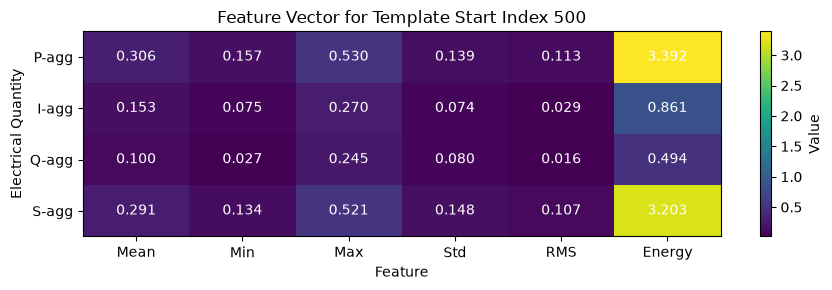

In [11]:
feature_names = ['Mean', 'Min', 'Max', 'Std', 'RMS', 'Energy']

template_index = int(next(iter(feature_lookup)))
feature_matrix = feature_lookup[template_index]

fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(feature_matrix, aspect='auto', cmap='viridis')

ax.set_xticks(range(len(feature_names)), labels=feature_names)
ax.set_yticks(range(len(agg_column_labels[2:])), labels=agg_column_labels[2:])
ax.set_xlabel('Feature')
ax.set_ylabel('Electrical Quantity')
ax.set_title(f'Feature Vector for Template Start Index {template_index}')

for row in range(feature_matrix.shape[0]):
    for col in range(feature_matrix.shape[1]):
        ax.text(col, row, f'{feature_matrix[row, col]:.3f}',
                ha='center', va='center', color='white')

fig.colorbar(im, ax=ax, label='Value')
plt.tight_layout()
plt.show()

#### Compute Feature Distances

Now for every combination of template (training frame) and query (validation or testing frame) we compute the feature distance between the two frames. 

`feature_distance_lookup` is a dictionary where each key is a tuple `(template_idx, query_idx)` and each item is the feature distance between the two frames. We can retrieve a specific distance with `feature_distance_lookup[(template_idx, query_idx)]`. 

In [13]:
# Compare every validation and test frame with every training template
query_indices = np.concatenate((val_indices, test_indices))

# Compare every query frame with every template and store distances for lookup
feature_distance_lookup = {}

for query_idx in tqdm(query_indices):
    query_features = feature_lookup[query_idx]

    for template_idx, template_features in feature_lookup.items():
        feature_distance_lookup[(int(template_idx), int(query_idx))] = float(
            feature_distance(template_features, query_features))

100%|██████████| 342/342 [00:00<00:00, 604.24it/s]


In [14]:
# Flatten the lookup dictionary for table display
feature_distance_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "feature distance": distance,
        }
        for (template_idx, query_idx), distance
        in feature_distance_lookup.items()])

display(feature_distance_df.head().style.set_caption('Feature Distance').hide(axis='index'))

template idx,query idx,feature distance
500,277,2.903394
851,277,0.330063
559,277,1.656885
845,277,1.259538
471,277,2.274879


### Pearson Correlation

Correlation provides another way to measure the distance between two frames of time-series data. Pearson correlation measures how strongly two variables move together in a linear way. 

Once again, we must remember that each frame is two-dimensional, as it contains time-series information for multiple electrical features. For each electrical feature, the function finds the correlation matrix, then selects the value comparing the two frames. The result ranges from -1 (opposing patterns) to +1 (strongly similar patterns). A value near 0 indicates little linear relationship.

The function returns the average absolut correlation over all electrical features.

In [15]:
def compute_correlation(frame1, frame2):
    
    correlations = [
        np.corrcoef(frame1[:, i], frame2[:, i])[0, 1]
        for i in range(frame1.shape[1])]

    return np.mean(np.abs(correlations))

In [16]:
# Compare every validation/test frame with every training template
pearson_correlation_lookup = {}

for query_idx in tqdm(query_indices):
    query_frame = agg_norm[query_idx : query_idx + window_length, 2:]

    for template_idx in train_indices:
        template_frame = agg_norm[template_idx : template_idx + window_length, 2:]
        pearson_correlation_lookup[(int(template_idx), int(query_idx))] = float(
            compute_correlation(template_frame, query_frame))

100%|██████████| 342/342 [00:14<00:00, 23.17it/s]


In [17]:
# Flatten the lookup dictionary for table display
pearson_correlation_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "pearson_correlation": correlation,
        }
        for (template_idx, query_idx), correlation
        in pearson_correlation_lookup.items()])

display(pearson_correlation_df.head().style.set_caption('Pearson Correlation').hide(axis='index'))

template idx,query idx,pearson_correlation
500,277,0.270804
851,277,0.481780
559,277,0.258226
845,277,0.778396
471,277,0.784573


### Dynamic Time Warping

Dynamic Time Warping (DTW) compares two frames of time-series data by aligning their points flexibly, allowing similar patterns to occur at different speeds or be shifted in time. DTW finds the lowest-cost alignment between the sequences. The `distance` is the accumulated cost of the optimal alignment. A smaller DTW distance means that the sequences are more similar. The `path` is the alignment as pairs of indices. Each pair indicates which point in the first sequence corresponds to a point in the second sequence. The same point may appear in multiple pairs. 

In [18]:
def compute_dtw(frame1, frame2):
    distance, path = fastdtw(
        frame1,
        frame2,
        dist=lambda x, y: np.linalg.norm(x - y))
    return distance, path

In [19]:
# Compare every validation/test frame with every training template
dtw_distance_lookup = {}

for query_idx in tqdm(query_indices):
    query_frame = agg_norm[query_idx : query_idx + window_length, 2:]

    for template_idx in train_indices:
        template_frame = agg_norm[template_idx : template_idx + window_length, 2:]
        distance, _ = compute_dtw(template_frame, query_frame)
        dtw_distance_lookup[(int(template_idx), int(query_idx))] = float(distance)

100%|██████████| 342/342 [09:41<00:00,  1.70s/it]


In [20]:
# Flatten the lookup dictionary for table display
dtw_distance_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "dtw distance": distance,
        }
        for (template_idx, query_idx), distance in dtw_distance_lookup.items()])

display(dtw_distance_df.head().style.set_caption('DTW Distance').hide(axis='index'))

template idx,query idx,dtw distance
500,277,11.780360
851,277,4.230345
559,277,5.775319
845,277,2.950938
471,277,4.254507


### Consolidate Distance Metrics

In [22]:
# consolidate feature_distance_lookup, pearson_correlation_lookup, and dtw_distance_lookup into one lookup dictionary
combined_lookup = {}

for key in feature_distance_lookup:
    template_idx, query_idx = key
    if key in pearson_correlation_lookup and key in dtw_distance_lookup:
        combined_lookup[key] = {
            "feature_distance": float(feature_distance_lookup[key]),
            "pearson_correlation": float(pearson_correlation_lookup[key]),
            "dtw_distance": float(dtw_distance_lookup[key]),
        }

combined_lookup_filepath = os.path.join(results_dir, 'combined_metric_lookup.pkl')
with open(combined_lookup_filepath, 'wb') as f:
    pickle.dump(combined_lookup, f)

In [23]:
combined_lookup_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "feature_distance": metrics["feature_distance"],
            "pearson_correlation": metrics["pearson_correlation"],
            "dtw_distance": metrics["dtw_distance"],
        }
        for (template_idx, query_idx), metrics in combined_lookup.items()])

display(combined_lookup_df.head().style.set_caption('Consolidated Distance Metrics').hide(axis='index'))

template idx,query idx,feature_distance,pearson_correlation,dtw_distance
500,277,2.903394,0.270804,11.780360
851,277,0.330063,0.481780,4.230345
559,277,1.656885,0.258226,5.775319
845,277,1.259538,0.778396,2.950938
471,277,2.274879,0.784573,4.254507
